In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_parquet("4FLG_Procesado.parquet")
df

,CLASS1,BlazarDist,Variability_Index,Frac_Variability,SpectrumType_LogParabola,SpectrumType_PowerLaw,SpectrumType_PLSuperExpCutoff,Energy_Flux100,LP_Index,LP_SigCurv,PL_Index,Pivot_Energy,Flux_Band_0,Flux_Band_4,Flux_Band_6,Flux_Band_7,nuFnu_Band_0,nuFnu_Band_4,nuFnu_Band_6,nuFnu_Band_7
0,bll,blazar,51.742390,0.429135,0,1,0,7.807578e-12,2.052470,1.283201,2.081634,2065.146729,1.664147e-12,1.866136e-10,1.364606e-11,1.204809e-12,2.657329e-16,1.268975e-12,9.279336e-13,2.075041e-13
1,bcu,blazar,25.609457,0.368921,1,0,0,3.260804e-12,1.580971,2.630329,1.781085,2729.530029,1.858900e-10,9.661182e-11,1.290118e-11,1.572634e-12,3.136423e-14,6.833589e-13,8.547137e-13,2.149872e-13
2,bcu,blazar,26.910145,0.937606,0,1,0,8.967048e-13,1.763400,0.958782,1.906426,4281.748047,3.287979e-11,2.881598e-11,4.228593e-16,1.748820e-12,5.286959e-15,2.000432e-13,2.935529e-17,3.234954e-13
3,bll,blazar,10.370596,0.000000,1,0,0,2.441939e-12,1.599259,3.092949,1.817964,3402.819092,4.485441e-09,6.530654e-11,5.156945e-12,4.613763e-17,7.668804e-13,4.618040e-13,3.346412e-13,5.758958e-18
4,other,non-blazar,7.720544,0.000000,1,0,0,4.373159e-12,2.641635,3.182654,2.518880,1996.203979,9.472302e-14,6.726024e-11,3.627743e-16,1.618911e-16,1.578786e-17,4.073829e-13,1.990180e-17,1.499963e-17
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2912,bcu,blazar,18.010399,0.259739,1,0,0,1.354165e-12,1.577917,3.787348,1.752499,5153.450684,6.129970e-12,4.413272e-11,1.857165e-12,5.640288e-17,1.062581e-15,3.169375e-13,1.105479e-13,5.420474e-18
2913,bll,blazar,14.498226,0.068273,0,1,0,4.093997e-12,1.924309,0.000000,1.928476,2930.842285,4.975796e-09,8.682364e-11,1.378831e-11,1.948438e-12,7.993894e-13,6.011633e-13,9.546973e-13,3.571405e-13
2914,bcu,blazar,6.934350,0.000000,1,0,0,1.116031e-12,2.639918,3.037318,2.714450,717.048584,2.112895e-08,4.710498e-12,8.963529e-15,3.741380e-15,3.582740e-12,2.547993e-14,4.679423e-16,3.466486e-16
2915,bcu,blazar,8.082824,0.000000,1,0,0,1.752340e-12,1.904424,2.774415,2.094933,1490.850708,8.510176e-14,6.003090e-11,1.787903e-12,1.558835e-19,1.431744e-17,3.939935e-13,1.071259e-13,1.637076e-20


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow import keras
from imblearn.over_sampling import SMOTE

In [4]:
# BlazarDist es binaria (0 = other, 1 = bll/bcu). CLASS1 se elimina porque es de donde sale la etiqueta.
smote = True

X_blazar = df.drop(columns=["CLASS1", "BlazarDist"]).astype("float32")
y_blazar = df["BlazarDist"].apply(lambda x: 1 if x == "blazar" else 0).astype("int32")

if smote:
    sm = SMOTE(random_state=42)
    X_blazar, y_blazar = sm.fit_resample(X_blazar, y_blazar)

# stratify mantiene la proporcion de clases en cada particion
x_train, x_test, y_train, y_test = train_test_split(
    X_blazar, y_blazar, test_size=0.2, stratify=y_blazar, random_state=42)

# El scaler se ajusta solo con train (evita fuga de informacion)
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

x_train, x_valid, y_train, y_valid = train_test_split(
    x_train, y_train, test_size=0.2, stratify=y_train, random_state=42)

print(x_train.shape, x_valid.shape, x_test.shape)

(2888, 18) (723, 18) (903, 18)


In [5]:
# Construccion del MLP
n_features = x_train.shape[1]   

model = keras.models.Sequential([
    keras.Input(shape=(n_features,)),
    # Capas ocultas
    keras.layers.Dense(300, activation="relu"),
    keras.layers.Dense(100, activation="relu"),
    # Clasificacion binaria: una neurona con sigmoide (probabilidad de ser blazar)
    keras.layers.Dense(1, activation="sigmoid")
])

In [6]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 300)            │         5,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,901 (140.24 KB)

 Trainable params: 35,901 (140.24 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Optimizador
optim = keras.optimizers.Adam(learning_rate=1e-3)
# Compilacion
model.compile(loss="binary_crossentropy",
              optimizer=optim,
              metrics=["accuracy"])
# Entrenamiento
history = model.fit(x_train, y_train, epochs=30, batch_size=64,
                    validation_data=(x_valid, y_valid))
# Evaluacion
model.evaluate(x_test, y_test)

Epoch 1/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.8494 - loss: 0.3961 - val_accuracy: 0.8963 - val_loss: 0.2741
Epoch 2/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8816 - loss: 0.2894 - val_accuracy: 0.9032 - val_loss: 0.2527
Epoch 3/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8934 - loss: 0.2606 - val_accuracy: 0.9059 - val_loss: 0.2418
Epoch 4/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8989 - loss: 0.2474 - val_accuracy: 0.9115 - val_loss: 0.2317
Epoch 5/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9006 - loss: 0.2426 - val_accuracy: 0.9087 - val_loss: 0.2329
Epoch 6/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9006 - loss: 0.2380 - val_accuracy: 0.9018 - val_loss: 0.2318
Epoch 7/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9034 - loss: 0.2317 - val_accuracy: 0.9156 - val_loss: 0.2170
Epoch 8/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9096 - loss: 0.2247 - val_accuracy: 0.9129 - val_loss

[0.2070513367652893, 0.9235880374908447]

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


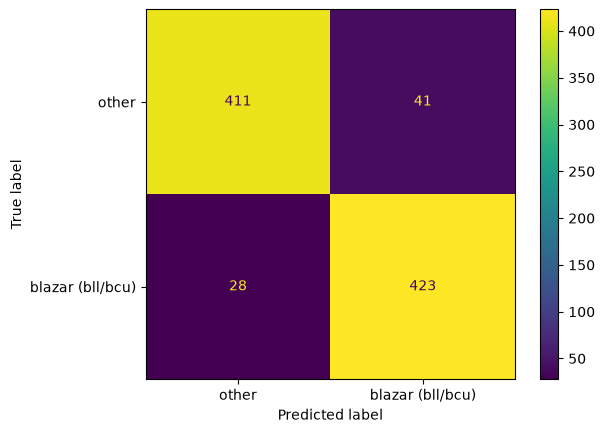

In [8]:
class_names = ["other", "blazar (bll/bcu)"]

# Prediccion: probabilidad de ser blazar
y_pred_prob = model.predict(x_test)
# Convertir probabilidades a clases con umbral 0.5
y_pred = (y_pred_prob.ravel() > 0.5).astype(int)
# Matriz de confusion
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot()
plt.show()

In [9]:
# BlazarDist es binaria (0 = other, 1 = bll/bcu). CLASS1 se elimina porque es de donde sale la etiqueta.
smote = False

X_class = df.drop(columns=["CLASS1", "BlazarDist"]).astype("float32")
y_class = df["CLASS1"].map({"other": 0, "bll": 1, "fsrq": 2, "bcu": 3}).astype("int32")

if smote:
    sm = SMOTE(random_state=42)
    X_class, y_class = sm.fit_resample(X_class, y_class)

# stratify mantiene la proporcion de clases en cada particion
x_train, x_test, y_train, y_test = train_test_split(
    X_class, y_class, test_size=0.2, stratify=y_class, random_state=42)

# El scaler se ajusta solo con train (evita fuga de informacion)
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

x_train, x_valid, y_train, y_valid = train_test_split(
    x_train, y_train, test_size=0.2, stratify=y_train, random_state=42)

print(x_train.shape, x_valid.shape, x_test.shape)

(1866, 18) (467, 18) (584, 18)


In [10]:
# Construccion del MLP
n_features = x_train.shape[1]   

model_mc = keras.models.Sequential([
    keras.Input(shape=(n_features,)),
    # Capas ocultas
    keras.layers.Dense(300, activation="relu"),
    keras.layers.Dense(100, activation="relu"),
    # Clasificacion multiclase: una neurona por clase con softmax (probabilidad de ser cada clase)
    keras.layers.Dense(4, activation="softmax")
])

In [11]:
# Optimizador
optim = keras.optimizers.Adam(learning_rate=1e-3)
# Compilacion
model_mc.compile(loss="sparse_categorical_crossentropy",
              optimizer=optim,
              metrics=["accuracy", "sparse_categorical_crossentropy", "f1_score"])
# Entrenamiento
history = model_mc.fit(x_train, y_train, epochs=30, batch_size=64,
                    validation_data=(x_valid, y_valid))
# Evaluacion
model_mc.evaluate(x_test, y_test)

Epoch 1/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.5895 - f1_score: 0.3966 - loss: 1.0155 - sparse_categorical_crossentropy: 1.0155 - val_accuracy: 0.6381 - val_f1_score: 0.3968 - val_loss: 0.8080 - val_sparse_categorical_crossentropy: 0.8080
Epoch 2/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6463 - f1_score: 0.4013 - loss: 0.8161 - sparse_categorical_crossentropy: 0.8161 - val_accuracy: 0.6574 - val_f1_score: 0.3984 - val_loss: 0.7366 - val_sparse_categorical_crossentropy: 0.7366
Epoch 3/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6699 - f1_score: 0.4007 - loss: 0.7771 - sparse_categorical_crossentropy: 0.7771 - val_accuracy: 0.6852 - val_f1_score: 0.4066 - val_loss: 0.7086 - val_sparse_categorical_crossentropy: 0.7086
Epoch 4/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6752 - f1_score: 0.4007 - loss: 0.7663 - sparse_categorical_crossentropy: 0.7663 - val_accuracy: 0.6831 - val_f1_score: 0.4011 - val_loss: 0.7002 - val_sparse_catego

[0.741504430770874,
 0.676369845867157,
 0.741504430770874,
 array([0.10967097, 0.71803844, 0.05649717, 0.7314286 ], dtype=float32)]

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step


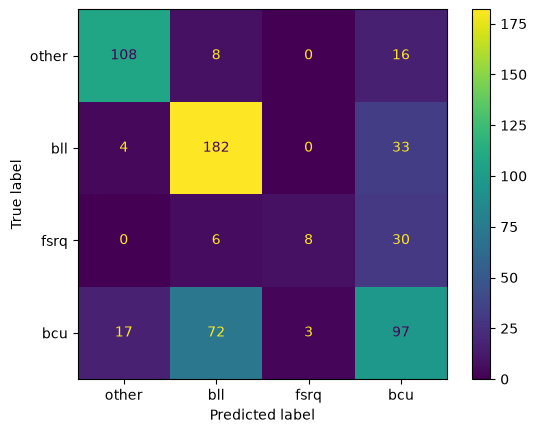

In [12]:
class_names = ["other", "bll", "fsrq", "bcu"]

# Prediccion: probabilidad de ser blazar
y_pred_prob = model_mc.predict(x_test)

y_pred = np.argmax(y_pred_prob, axis=1)

if len(y_test.shape) > 1 and y_test.shape[1] > 1:
    y_true = np.argmax(y_test, axis=1)
else:
    y_true = y_test

# Matriz de confusion
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot()
plt.show()